In [50]:
import pandas as pd


default_file_path = "../../data/raw/"
save_file_path = "../../data/iterim/"


def convert_integer_column(df_column: pd.Series):
    converted_column = df_column.astype("string").str.replace(" ", "", regex=False).str.replace(",", ".", regex=False).str.replace("\u00a0", "", regex=False).str.replace("—", "-", regex=False)
    converted_column = pd.to_numeric(converted_column, errors="coerce")
    return converted_column.round(2)


def convert_datetime_column(df_column: pd.Series):
    converted_column = pd.to_datetime(df_column, errors="coerce", format="mixed")
    return converted_column


def convert_string_column(df_column: pd.Series):
    convert_column = df_column.astype("string").str.replace(" ", "_").str.lower().str.strip()
    return convert_column

In [51]:
sources_df = pd.read_csv(f"{base_file_path}sources.csv")
wells_df = pd.read_parquet(f"{save_file_path}wells.parquet")

In [58]:
display(sources_df)
display(sources_df.dtypes)

,source_id,name,x,y,z_top,z_bottom,start_date,end_date,estimated_release_rate_g_day
0,SRC-01,Цех обезжиривания,575.0,1575.0,0,-20,2019-01-01,NaT,78.0
1,SRC-02,Шламонакопитель,1075.0,1775.0,-20,-46,2020-02-01,2024-08-31,31.0
2,SRC-03,Разлив у склада,1725.0,1425.0,-20,-46,2022-05-01,2023-02-28,49.0


source_id                                  str
name                                       str
x                                      Float64
y                                      Float64
z_top                                    Int64
z_bottom                                 Int64
start_date                      datetime64[us]
end_date                        datetime64[us]
estimated_release_rate_g_day           Float64
dtype: object

|Таблица sources показывает источники загрязнений и их выбросы в день

In [53]:
sources_df["x"] = sources_df["x"].astype("string").str.replace(" ", "", regex=False).str.replace("-", "-", regex=False).str.replace("\u00a0", "", regex=False)
sources_df["y"] = sources_df["y"].astype("string").str.replace(" ", "", regex=False).str.replace("-", "-", regex=False).str.replace("\u00a0", "", regex=False)
sources_df["z_top"] = sources_df["z_top"].astype("string").str.replace(" ", "", regex=False).str.replace("-", "-", regex=False).str.replace("\u00a0", "", regex=False)
sources_df["z_bottom"] = sources_df["z_bottom"].astype("string").str.replace(" ", "", regex=False).str.replace("-", "-", regex=False).str.replace("\u00a0", "", regex=False)

sources_df["estimated_release_rate_g_day"]= sources_df["estimated_release_rate_g_day"].astype("string").str.replace(" ", "", regex=False).str.replace("-", "-", regex=False).str.replace("\u00a0", "", regex=False)

In [54]:
sources_df["x"] = pd.to_numeric(sources_df["x"], errors="coerce")
sources_df["y"] = pd.to_numeric(sources_df["y"], errors="coerce")
sources_df["z_top"] = pd.to_numeric(sources_df["z_top"], errors="coerce")
sources_df["z_bottom"] = pd.to_numeric(sources_df["z_bottom"], errors="coerce")

sources_df["estimated_release_rate_g_day"] = pd.to_numeric(sources_df["estimated_release_rate_g_day"], errors="coerce")

sources_df["end_date"] = pd.to_datetime(sources_df["end_date"], format="mixed", errors="coerce")
sources_df["start_date"] = pd.to_datetime(sources_df["start_date"], format="mixed", errors="coerce")

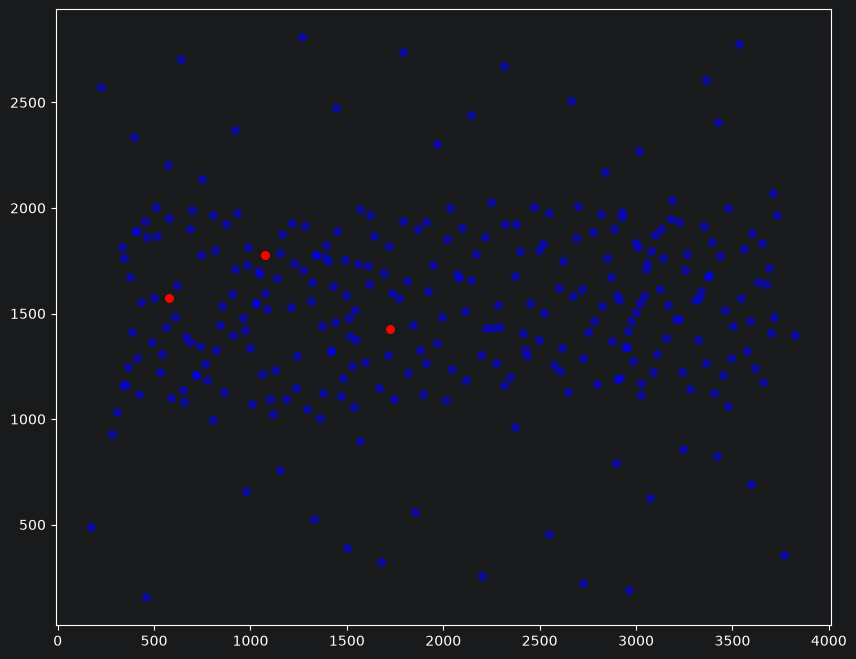

In [56]:
plt.figure(figsize=(10,8))
plt.scatter(x=sources_df["x"], y=sources_df["y"], s=30, color="red")
plt.scatter(x=wells_df["x"], y=wells_df["y"], s=30, color="blue", alpha=0.5)

In [57]:
sources_df.to_parquet(f"{save_file_path}sources.parquet", engine="pyarrow")